# ДЗ 8. Графики для менеджера: Matplotlib и Seaborn
Срок: **до воскресенья 29.11, 24:00**.
Сдача: папка `hw08` репозитория `dsa-homework` (`hw08.ipynb`): `git add hw08` → `git commit` → `git push`, ссылку прикрепите в LMS. Перед сдачей запустите все ячейки, чтобы графики были видны в GitHub.

Каждый график: **заголовок-вывод, подписи осей с единицами, рядом число, которым проверен заголовок**. Под графиком – вывод для менеджера (в print или Markdown-ячейке): что видно и что делать.

Инструменты: всё с уроков 1–8. Если берёте непройденный инструмент, объясните его в комментарии.

- **[База]** обязательно для всех · **[Стандарт]** сколько получится · **[Челлендж]** для тех, кому легко.

## [Для всех] Чтение кода: без запуска
Сначала напишите ответ и «почему», потом запустите.
```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 1
fig, ax = plt.subplots()
pd.Series([3, 1, 2], index=["a", "b", "c"]).sort_values().plot(kind="bar", ax=ax)
print([t.get_text() for t in ax.get_xticklabels()])
# 2
fig, axes = plt.subplots(1, 3)
print(axes.shape)
# 3
fig, ax = plt.subplots()
sns.barplot(x=["a", "a", "b"], y=[10, 30, 5], ax=ax)
print([float(b.get_height()) for b in ax.patches])
# 4
counts, edges = np.histogram([10, 20, 30, 40], bins=2)
print(counts, edges)
# 5
fig, (a1, a2) = plt.subplots(1, 2)
a1.plot([1, 2], [95, 100])
a2.bar([1, 2], [95, 100])
print(a1.get_ylim()[0] > 0, a2.get_ylim()[0])
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

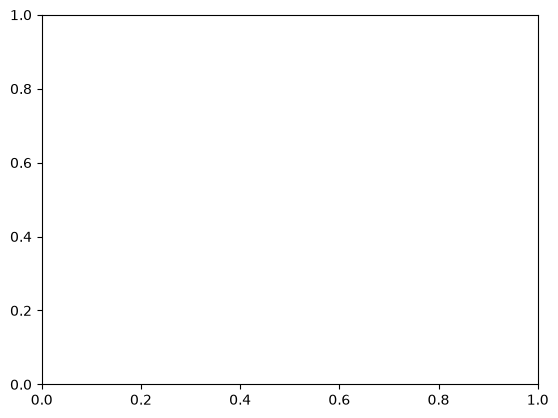

In [2]:
fig, ax = plt.subplots()

In [3]:
pd.Series([3, 1, 2], index=["b", "c", "a"]).sort_values()

c    1
a    2
b    3
dtype: int64

In [4]:
pd.Series([3, 1, 2], index=["a", "b", "c"]).sort_values().plot(kind="bar", ax=ax)
print([t.get_text() for t in ax.get_xticklabels()])

['b', 'c', 'a']


Ваши ответы и объяснения:

1. `['b', 'c', 'a']`. Сортировка идёт по значениям `1, 2, 3`, подписи следуют за ними.
2. `(3,)`. Возвращается одномерный массив из трёх областей с осями.
3. `[20.0, 5.0]`. `barplot` по умолчанию считает среднее: для `a` это `(10 + 30) / 2`.
4. `[2 2] [10. 25. 40.]`. Две корзины имеют границы 10, 25, 40, в каждую попадают два числа.
5. `True 0.0`. У линии нижняя граница автоматически близка к 95, а столбики начинаются от нуля.

In [5]:
# Загрузка orders.csv: в Colab нажмите «Выбрать файлы» и укажите orders.csv из LMS.
# Если файл уже лежит рядом с ноутбуком, загрузка пропускается.
import os
if not os.path.exists("orders.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        print("Положите orders.csv в одну папку с ноутбуком")
print("orders.csv на месте:", os.path.exists("orders.csv"))

orders.csv на месте: True


In [6]:
# Очистка урока 6 одной ячейкой: суммы, города, дубли, даты, TEST
import pandas as pd
import numpy as np

CITY = {"алматы": "Алматы", "almaty": "Алматы", "астана": "Астана", "astana": "Астана",
        "шымкент": "Шымкент", "shymkent": "Шымкент", "караганда": "Караганда",
        "актобе": "Актобе", "атырау": "Атырау"}

df = pd.read_csv("orders.csv")
df["amount"] = pd.to_numeric(df["amount"].str.replace(" ", ""))
df["city"] = df["city"].str.strip().str.lower().map(CITY)
df = df.drop_duplicates()
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df = df[df["customer_id"] != "TEST"].copy()    # copy: дальше добавим столбцы
df.shape

(5280, 9)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

df["cancel"] = df["status"] == "отменён"     # True/False, урок 7
paid = df[df["status"] == "оплачен"]
len(paid)

4739

Можно вместо ячейки очистки взять свою функцию `clean()` из ДЗ 6. Проверка: 5 280 строк, 4 739 оплаченных.

## [База] 1. Дни недели
В ДЗ 6 меньше всего заказов было в понедельник. Нарисуйте число заказов по дням недели столбиками **в порядке пн → вс** с подписями «пн», «вт», … (подсказка: `.dt.day_of_week` даёт 0 для понедельника, `value_counts().sort_index()`).
Проверьте высоты столбиков (`ax.patches`) против таблицы. Почему `value_counts()` без `sort_index()` здесь не подходит?

день  заказов
  пн      684
  вт      785
  ср      774
  чт      786
  пт      781
  сб      773
  вс      697


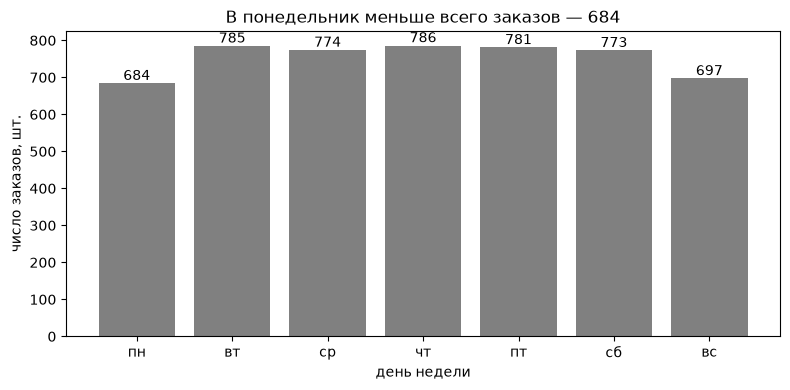

Высоты столбиков: [684, 785, 774, 786, 781, 773, 697]
Совпадают с таблицей: True
value_counts() без sort_index() ставит дни по числу заказов, поэтому календарный порядок нарушается.
Для менеджера: учитывайте меньшую нагрузку в понедельник при планировании смен курьеров.


In [8]:
# 1
weekday_counts = df["order_date"].dt.day_of_week.value_counts().sort_index()
weekday_names = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]
print(pd.DataFrame({"день": weekday_names, "заказов": weekday_counts.values}).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(weekday_names, weekday_counts.values, color="gray")
ax.bar_label(bars)
ax.set_title(f"В понедельник меньше всего заказов — {weekday_counts.loc[0]}")
ax.set_xlabel("день недели")
ax.set_ylabel("число заказов, шт.")
fig.tight_layout()
plt.show()

heights = [int(bar.get_height()) for bar in ax.patches]
print("Высоты столбиков:", heights)
print("Совпадают с таблицей:", heights == weekday_counts.tolist())
print("value_counts() без sort_index() ставит дни по числу заказов, поэтому календарный порядок нарушается.")
print("Для менеджера: учитывайте меньшую нагрузку в понедельник при планировании смен курьеров.")

## [База] 2. Категории: сентябрь и октябрь
Выручка оплаченных по категориям и месяцам (`pivot_table`, урок 7). Два графика рядом (`plt.subplots(1, 2)`): слева выручка сентября и октября столбиками (`pc[[9, 10]].plot(kind="barh", ax=axes[0])`), справа изменение в %, отсортировано, самая падающая категория цветом.
Какая категория падает сильнее всех? Сходится с ДЗ 4 и ДЗ 7?

Выручка оплаченных, ₸:
month                9           10
category                           
Дом           4997730.0   5125790.0
Книги         1065300.0   1140910.0
Красота       2610950.0   2678990.0
Одежда        9167100.0   8505730.0
Электроника  17402330.0  16968100.0
Изменение, %:
category
Одежда        -7.21
Электроника   -2.50
Дом            2.56
Красота        2.61
Книги          7.10


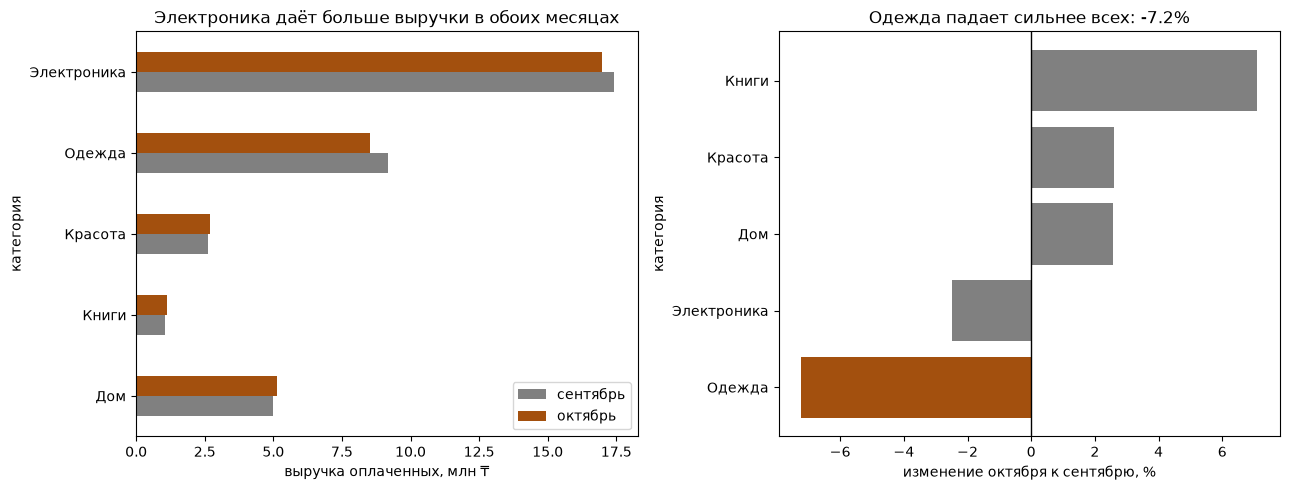

Электроника: 17,402,330 ₸ в сентябре и 16,968,100 ₸ в октябре.
Для менеджера: изменение выручки Одежды на -7.2% совпадает с ДЗ 4 и 7; проверьте, в каких городах и заказах этой категории выросли отмены.


In [9]:
# 2
pc = paid.pivot_table(index="category", columns="month", values="amount", aggfunc="sum")
category_change = ((pc[10] / pc[9] - 1) * 100).sort_values()
worst_category = category_change.index[0]
print("Выручка оплаченных, ₸:")
print(pc.to_string())
print("Изменение, %:")
print(category_change.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
(pc[[9, 10]] / 1e6).plot(kind="barh", ax=axes[0], color=["gray", "#A3500E"])
axes[0].set_title("Электроника даёт больше выручки в обоих месяцах")
axes[0].set_xlabel("выручка оплаченных, млн ₸")
axes[0].set_ylabel("категория")
axes[0].legend(["сентябрь", "октябрь"])
colors = ["#A3500E" if c == worst_category else "gray" for c in category_change.index]
axes[1].barh(category_change.index, category_change.values, color=colors)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title(f"Одежда падает сильнее всех: {category_change.loc['Одежда']:.1f}%")
axes[1].set_xlabel("изменение октября к сентябрю, %")
axes[1].set_ylabel("категория")
fig.tight_layout()
plt.show()

print(f"Электроника: {pc.loc['Электроника', 9]:,.0f} ₸ в сентябре и {pc.loc['Электроника', 10]:,.0f} ₸ в октябре.")
print(f"Для менеджера: изменение выручки Одежды на {category_change.loc['Одежда']:.1f}% совпадает с ДЗ 4 и 7; "
      "проверьте, в каких городах и заказах этой категории выросли отмены.")

## [База] 3. Выручка компании по дням
Выручка оплаченных по дням линией (`groupby` по `.dt.date`). Отметьте 1 октября вертикальной линией (`ax.axvline`). Найдите день с минимальной и максимальной выручкой.
Видно ли на этом графике падение на 2,3%? Сравните разброс выручки по дням (`std`) с разницей средних за день в сентябре и октябре.

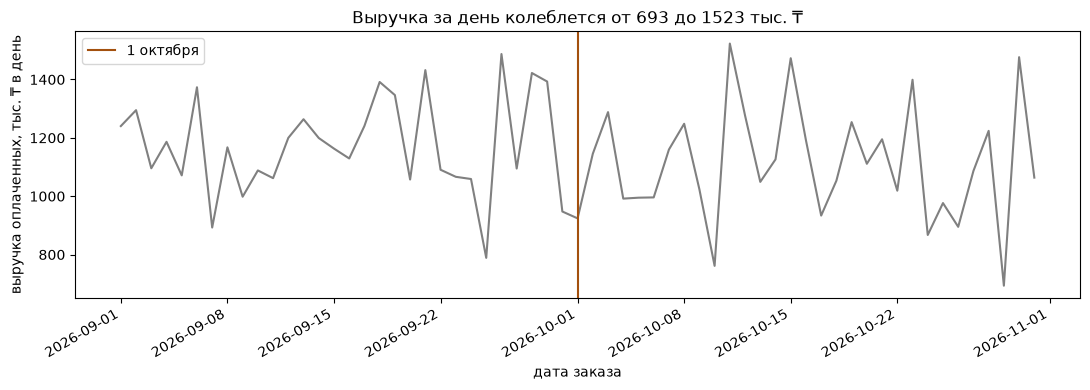

Минимум: 29.10.2026, 693,290 ₸.
Максимум: 11.10.2026, 1,523,030 ₸.
Среднее сентября: 1,174,780 ₸ за день на 30 днях; октября: 1,110,307 ₸ на 31 днях.
Стандартное отклонение по 61 дням: 186,516 ₸; разница средних за день: -64,473 ₸.
Выручка за месяц изменилась на -2.34%; в октябре 31 день, в сентябре 30.
Для менеджера: на дневной линии небольшое месячное снижение теряется среди колебаний; сравнивайте также суммы за месяц и показатели отдельных городов.


In [10]:
# 3
daily_revenue = paid.groupby(paid["order_date"].dt.date)["amount"].sum()
daily_revenue.index = pd.to_datetime(daily_revenue.index)
min_day = daily_revenue.sort_values().index[0]
max_day = daily_revenue.sort_values().index[-1]
september_daily = daily_revenue[daily_revenue.index.month == 9]
october_daily = daily_revenue[daily_revenue.index.month == 10]
daily_std = daily_revenue.std()
mean_difference = october_daily.mean() - september_daily.mean()
monthly_revenue = paid.groupby("month")["amount"].sum()
monthly_change = monthly_revenue.loc[10] / monthly_revenue.loc[9] - 1

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily_revenue.index, daily_revenue.values / 1000, color="gray")
ax.axvline(pd.Timestamp("2026-10-01"), color="#A3500E", label="1 октября")
ax.set_title(f"Выручка за день колеблется от {daily_revenue.min() / 1000:.0f} до {daily_revenue.max() / 1000:.0f} тыс. ₸")
ax.set_xlabel("дата заказа")
ax.set_ylabel("выручка оплаченных, тыс. ₸ в день")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

print(f"Минимум: {min_day:%d.%m.%Y}, {daily_revenue.loc[min_day]:,.0f} ₸.")
print(f"Максимум: {max_day:%d.%m.%Y}, {daily_revenue.loc[max_day]:,.0f} ₸.")
print(f"Среднее сентября: {september_daily.mean():,.0f} ₸ за день на {len(september_daily)} днях; "
      f"октября: {october_daily.mean():,.0f} ₸ на {len(october_daily)} днях.")
print(f"Стандартное отклонение по {len(daily_revenue)} дням: {daily_std:,.0f} ₸; "
      f"разница средних за день: {mean_difference:,.0f} ₸.")
print(f"Выручка за месяц изменилась на {monthly_change:+.2%}; в октябре 31 день, в сентябре 30.")
print("Для менеджера: на дневной линии небольшое месячное снижение теряется среди колебаний; "
      "сравнивайте также суммы за месяц и показатели отдельных городов.")

## [Стандарт] 4. Исправьте код от AI
AI нарисовал график и пишет менеджеру: «Выручка в Шымкенте отстаёт от Алматы в разы».
```python
sns.barplot(data=df, x="city", y="amount")
plt.ylim(13500, 15500)
plt.title("Выручка по городам: Шымкент отстаёт в разы")
plt.show()
```
В коде **три** ошибки. Найдите их (проверьте высоты столбиков через `ax.patches`), нарисуйте правильный график выручки и напишите менеджеру, что на самом деле отличает Шымкент: уровень выручки или её изменение?

Высоты столбиков ошибочного barplot, ₸:
Алматы       14923.82
Астана       14553.87
Караганда    14919.00
Шымкент      14105.62
Атырау       14648.32
Актобе       14448.94
Средний amount по всем статусам, ₸:
city
Актобе       14448.94
Алматы       14923.82
Астана       14553.87
Атырау       14648.32
Караганда    14919.00
Шымкент      14105.62


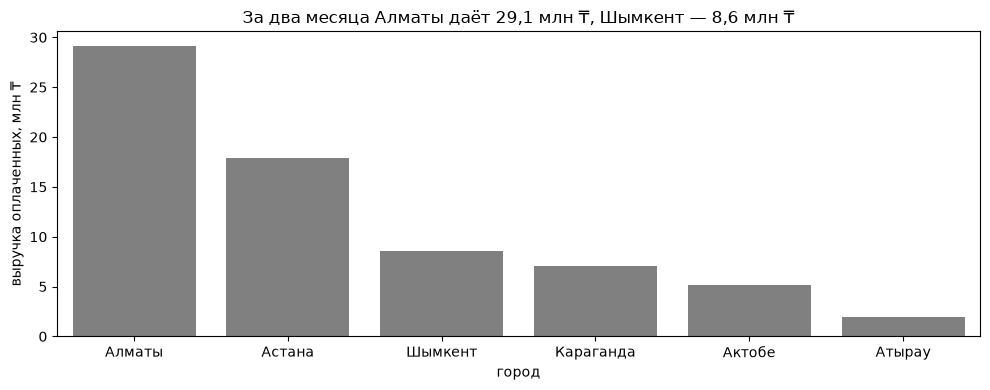

Высоты исправленного графика и суммы по таблице, ₸:
               график     таблица
city                             
Алматы     29144090.0  29144090.0
Астана     17884750.0  17884750.0
Шымкент     8602660.0   8602660.0
Караганда   7020200.0   7020200.0
Актобе      5117380.0   5117380.0
Атырау      1893850.0   1893850.0
Изменение выручки по городам, %:
city
Актобе       -1.42
Алматы        0.98
Астана       -2.03
Атырау        4.96
Караганда    -7.59
Шымкент     -11.29
Для менеджера: у Алматы выше общий объём выручки, а Шымкент выделяется самым сильным снижением (-11.3%); проверьте отмены и доставку.


In [11]:
# 4
# Ошибки: barplot по умолчанию считает среднее, в df есть отмены, ось Y обрезана.
city_order = df["city"].unique()
fig, wrong_ax = plt.subplots()
sns.barplot(data=df, x="city", y="amount", order=city_order, errorbar=None, ax=wrong_ax)
wrong_heights = [bar.get_height() for bar in wrong_ax.patches]
print("Высоты столбиков ошибочного barplot, ₸:")
print(pd.Series(wrong_heights, index=city_order).round(2).to_string())
print("Средний amount по всем статусам, ₸:")
print(df.groupby("city")["amount"].mean().round(2).to_string())
plt.close(fig)

city_revenue = paid.groupby("city")["amount"].sum().sort_values(ascending=False)
paid_plot = paid.copy()
paid_plot["amount_million"] = paid_plot["amount"] / 1e6
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=paid_plot, x="city", y="amount_million", estimator="sum", errorbar=None,
            order=city_revenue.index, color="gray", ax=ax)
ax.set_ylim(bottom=0)
ax.set_title("За два месяца Алматы даёт 29,1 млн ₸, Шымкент — 8,6 млн ₸")
ax.set_xlabel("город")
ax.set_ylabel("выручка оплаченных, млн ₸")
fig.tight_layout()
plt.show()

correct_heights = pd.Series([bar.get_height() * 1e6 for bar in ax.patches], index=city_revenue.index)
print("Высоты исправленного графика и суммы по таблице, ₸:")
print(pd.DataFrame({"график": correct_heights, "таблица": city_revenue}).to_string())
city_month = paid.pivot_table(index="city", columns="month", values="amount", aggfunc="sum")
city_change = (city_month[10] / city_month[9] - 1) * 100
print("Изменение выручки по городам, %:")
print(city_change.round(2).to_string())
print("Для менеджера: у Алматы выше общий объём выручки, а Шымкент выделяется самым сильным "
      f"снижением ({city_change.loc['Шымкент']:.1f}%); проверьте отмены и доставку.")

## [Стандарт] 5. Город или срок доставки?
Тепловая карта «город × срок доставки»: доля отмен (`annot=True`, `fmt=".0%"`). Рядом вторая тепловая карта: число заказов в каждой клетке (`fmt=".0f"`).
Отменяют ли в Шымкенте чаще, чем в других городах, **при одинаковом сроке доставки**? Посчитайте долю отмен в Шымкенте и в остальных городах только для заказов со сроком ≤ 3 дня. Что это значит для решения менеджера?

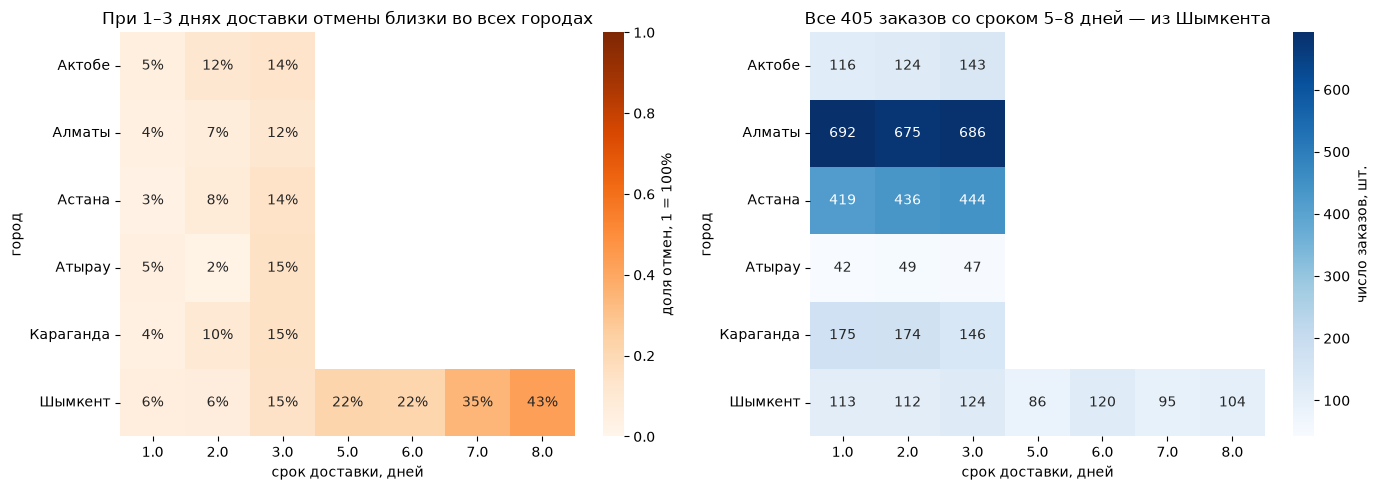

Доля отмен при сроке не более 3 дней:
Остальные города: 8.52% на 4368 заказах.
Шымкент: 9.17% на 349 заказах.
Отмены при одинаковом сроке, %:
delivery_days   1.0    2.0    3.0    5.0    6.0    7.0    8.0
city                                                         
Актобе         5.17  12.10  13.99    NaN    NaN    NaN    NaN
Алматы         4.34   7.26  12.10    NaN    NaN    NaN    NaN
Астана         3.34   8.26  14.19    NaN    NaN    NaN    NaN
Атырау         4.76   2.04  14.89    NaN    NaN    NaN    NaN
Караганда      4.00   9.77  15.07    NaN    NaN    NaN    NaN
Шымкент        6.19   6.25  14.52  22.09  21.67  34.74  43.27
Число заказов в каждой клетке:
delivery_days    1.0    2.0    3.0   5.0    6.0   7.0    8.0
city                                                        
Актобе         116.0  124.0  143.0   0.0    0.0   0.0    0.0
Алматы         692.0  675.0  686.0   0.0    0.0   0.0    0.0
Астана         419.0  436.0  444.0   0.0    0.0   0.0    0.0
Атырау          42.0   49.

In [12]:
# 5
cancel_heatmap = df.pivot_table(index="city", columns="delivery_days", values="cancel", aggfunc="mean")
count_heatmap = df.pivot_table(index="city", columns="delivery_days", values="order_id", aggfunc="count")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cancel_heatmap, annot=True, fmt=".0%", cmap="Oranges", vmin=0, vmax=1,
            cbar_kws={"label": "доля отмен, 1 = 100%"}, ax=axes[0])
axes[0].set_title("При 1–3 днях доставки отмены близки во всех городах")
axes[0].set_xlabel("срок доставки, дней")
axes[0].set_ylabel("город")
sns.heatmap(count_heatmap, annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "число заказов, шт."}, ax=axes[1])
axes[1].set_title("Все 405 заказов со сроком 5–8 дней — из Шымкента")
axes[1].set_xlabel("срок доставки, дней")
axes[1].set_ylabel("город")
fig.tight_layout()
plt.show()

short = df[df["delivery_days"] <= 3].copy()
short["is_sh"] = short["city"] == "Шымкент"
short_summary = short.groupby("is_sh").agg(orders=("order_id", "count"),
                                            cancel_share=("cancel", "mean"))
print("Доля отмен при сроке не более 3 дней:")
for is_sh, count, rate in zip(short_summary.index, short_summary["orders"], short_summary["cancel_share"]):
    name = "Шымкент" if is_sh else "Остальные города"
    print(f"{name}: {rate:.2%} на {count} заказах.")
print("Отмены при одинаковом сроке, %:")
print((cancel_heatmap * 100).round(2).to_string())
print("Число заказов в каждой клетке:")
print(count_heatmap.fillna(0).to_string())
print("Заказов со сроком 5–8 дней:", ((df["delivery_days"] >= 5) & (df["delivery_days"] <= 8)).sum())
print("Заказов с неизвестным сроком, не вошедших в карты:", df["delivery_days"].isna().sum())
print("Для менеджера: при одинаковых быстрых сроках большого превышения отмен в Шымкенте нет. "
      "Для долгих сроков сравнения с другими городами в данных нет; начните с восстановления быстрой доставки.")

## [Стандарт] 6. Выбросы на ящике с усами
Ящик с усами: чек оплаченных по категориям. Посчитайте, сколько точек-выбросов в каждой категории по правилу 1,5 IQR (`groupby("category")["amount"].quantile(0.25)` и `0.75`).
В ДЗ 5 одна граница на всех (около 38 тыс. ₸) записала в выбросы почти только Электронику. Сколько выбросов теперь и в каких категориях? Какой подход честнее и почему?

                Q1_₸     Q3_₸  нижняя_₸  верхняя_₸  оплаченных  выбросов
category                                                                
Дом           7310.0  12912.5  -1093.75   21316.25         952        32
Книги         2727.5   4700.0   -231.25    7658.75         564        18
Красота       3950.0   7560.0  -1465.00   12975.00         857        35
Одежда        8922.5  16247.5  -2065.00   27235.00        1330        48
Электроника  22537.5  39537.5  -2962.50   65037.50        1036        43
Всего выбросов по категориям: 176 из 4739
Общая верхняя граница: 37,940 ₸, выбросов: 310.
Выбросы при общей границе:
category
Дом              2
Одежда           9
Электроника    299


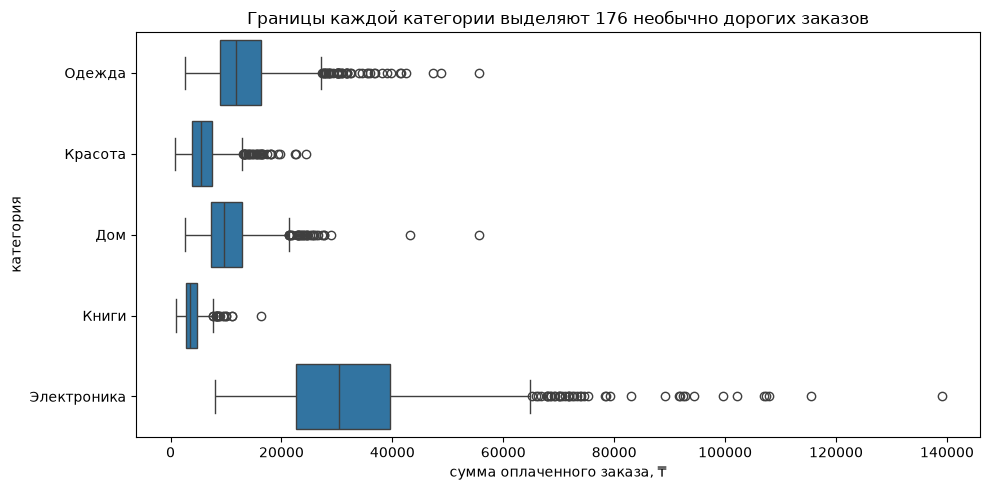

Для менеджера: проверяйте необычные чеки внутри категории, поскольку обычная цена электроники выше цены книги. Точки за усами требуют проверки, автоматическое удаление таких заказов исказит выручку.


In [13]:
# 6
q1 = paid.groupby("category")["amount"].quantile(0.25)
q3 = paid.groupby("category")["amount"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
is_outlier = ((paid["amount"] < paid["category"].map(lower)) |
              (paid["amount"] > paid["category"].map(upper)))
outliers = paid.loc[is_outlier].groupby("category").size()
outlier_table = pd.DataFrame({"Q1_₸": q1, "Q3_₸": q3, "нижняя_₸": lower, "верхняя_₸": upper,
                              "оплаченных": paid.groupby("category").size(), "выбросов": outliers})
outlier_table["выбросов"] = outlier_table["выбросов"].fillna(0)
print(outlier_table.round(2).to_string())
print("Всего выбросов по категориям:", is_outlier.sum(), "из", len(paid))

all_q1 = paid["amount"].quantile(0.25)
all_q3 = paid["amount"].quantile(0.75)
all_iqr = all_q3 - all_q1
global_outlier = (paid["amount"] < all_q1 - 1.5 * all_iqr) | (paid["amount"] > all_q3 + 1.5 * all_iqr)
print(f"Общая верхняя граница: {all_q3 + 1.5 * all_iqr:,.0f} ₸, выбросов: {global_outlier.sum()}.")
print("Выбросы при общей границе:")
print(paid.loc[global_outlier].groupby("category").size().to_string())

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=paid, x="amount", y="category", ax=ax)
ax.set_title(f"Границы каждой категории выделяют {is_outlier.sum()} необычно дорогих заказов")
ax.set_xlabel("сумма оплаченного заказа, ₸")
ax.set_ylabel("категория")
fig.tight_layout()
plt.show()
print("Для менеджера: проверяйте необычные чеки внутри категории, поскольку обычная цена электроники выше цены книги. "
      "Точки за усами требуют проверки, автоматическое удаление таких заказов исказит выручку.")

## [Челлендж] 7. Две оси от AI
AI нарисовал по Шымкенту заказы в день и выручку в день на двух осях (`ax.twinx()`) и пишет: «Линии идут вместе, всё в порядке». Две оси позволяют подогнать любые две линии друг к другу.
Нарисуйте честно, на одной оси: число заказов в день и выручку оплаченных в день в Шымкенте, обе как **индекс к среднему дню сентября = 100**. Какой индекс у каждой линии в среднем за октябрь? Что это говорит об отменах?

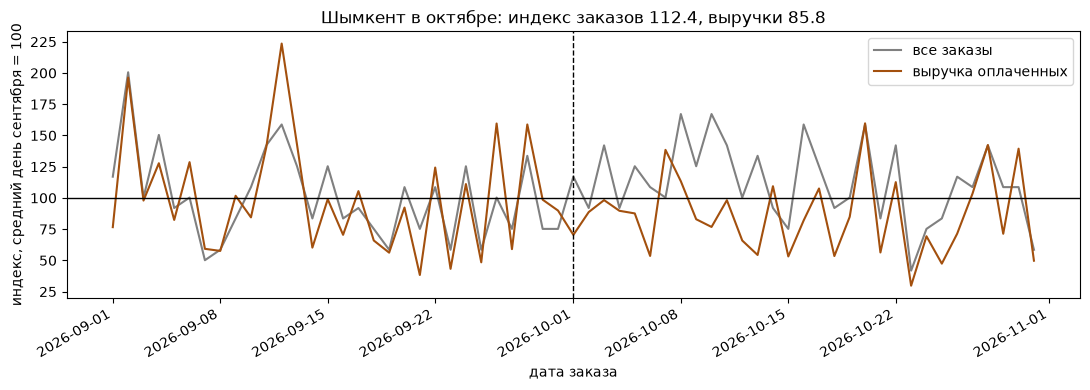

База сентября: 11.97 заказа и 151,955.00 ₸ в день на 30 днях.
Средние индексы октября на 31 дне: заказы 112.41, выручка 85.85.
Отмены по месяцам:
         mean  count
month               
9      0.0891    359
10     0.3070    417
Для менеджера: заказов за день стало больше, а выручки меньше. Проверьте рост отмен с 8,9% до 30,7% и работу доставки Шымкента.


In [14]:
# 7
sh = df[df["city"] == "Шымкент"]
sh_paid = paid[paid["city"] == "Шымкент"]
daily_orders = sh.groupby(sh["order_date"].dt.date).size()
daily_revenue_sh = sh_paid.groupby(sh_paid["order_date"].dt.date)["amount"].sum()
daily_orders.index = pd.to_datetime(daily_orders.index)
daily_revenue_sh.index = pd.to_datetime(daily_revenue_sh.index)
# reindex выравнивает даты выручки с датами заказов; день без оплаты получает 0.
daily_revenue_sh = daily_revenue_sh.reindex(daily_orders.index, fill_value=0)
base_orders = daily_orders[daily_orders.index.month == 9].mean()
base_revenue = daily_revenue_sh[daily_revenue_sh.index.month == 9].mean()
order_index = daily_orders / base_orders * 100
revenue_index = daily_revenue_sh / base_revenue * 100
oct_order_index = order_index[order_index.index.month == 10].mean()
oct_revenue_index = revenue_index[revenue_index.index.month == 10].mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(order_index.index, order_index.values, color="gray", label="все заказы")
ax.plot(revenue_index.index, revenue_index.values, color="#A3500E", label="выручка оплаченных")
ax.axhline(100, color="black", linewidth=1)
ax.axvline(pd.Timestamp("2026-10-01"), color="black", linestyle="--", linewidth=1)
ax.set_title(f"Шымкент в октябре: индекс заказов {oct_order_index:.1f}, выручки {oct_revenue_index:.1f}")
ax.set_xlabel("дата заказа")
ax.set_ylabel("индекс, средний день сентября = 100")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

print(f"База сентября: {base_orders:.2f} заказа и {base_revenue:,.2f} ₸ в день на 30 днях.")
print(f"Средние индексы октября на 31 дне: заказы {oct_order_index:.2f}, выручка {oct_revenue_index:.2f}.")
print("Отмены по месяцам:")
print(sh.groupby("month")["cancel"].agg(["mean", "count"]).round(4).to_string())
print("Для менеджера: заказов за день стало больше, а выручки меньше. "
      "Проверьте рост отмен с 8,9% до 30,7% и работу доставки Шымкента.")

## [Челлендж] 8. Plotly: найти момент сбоя
Точечный график заказов Шымкента 28.09–03.10: `px.scatter(x="order_date", y="delivery_days", color="status", hover_data=["order_id"])`. Наведением найдите последний заказ с быстрой доставкой (≤ 3 дня) и первый медленный (≥ 5 дней).
Проверьте ответ кодом Pandas (фильтр и `sort_values`). GitHub не покажет график Plotly, поэтому ответ напишите текстом.

In [15]:
# 8
import plotly.express as px

window = df[(df["city"] == "Шымкент") & (df["order_date"] >= "2026-09-28") &
            (df["order_date"] < "2026-10-04")].sort_values("order_date")
last_fast = window[window["delivery_days"] <= 3].sort_values("order_date").iloc[-1]
first_slow = window[window["delivery_days"] >= 5].sort_values("order_date").iloc[0]

fig = px.scatter(window, x="order_date", y="delivery_days", color="status", hover_data=["order_id"],
                 title="С 1 октября наблюдаемые сроки доставки Шымкента растут с 1–3 до 5–8 дней",
                 labels={"order_date": "дата и время заказа", "delivery_days": "срок доставки, дней",
                         "status": "статус", "order_id": "номер заказа"})
fig.show()

print(f"Последний быстрый заказ: №{last_fast['order_id']}, {last_fast['order_date']:%d.%m.%Y %H:%M}, "
      f"срок {last_fast['delivery_days']:.0f} дня.")
print(f"Первый медленный заказ: №{first_slow['order_id']}, {first_slow['order_date']:%d.%m.%Y %H:%M}, "
      f"срок {first_slow['delivery_days']:.0f} дней.")
print("Заказов в окне:", len(window), "с известным сроком:", window["delivery_days"].count())
print("Диапазон сроков по датам, дней:")
print(window.groupby(window["order_date"].dt.date)["delivery_days"].agg(["min", "max", "count"]).to_string())
print("Для менеджера: граница сбоя лежит между этими двумя заказами; проверьте изменения в работе "
      "курьерской службы на 1 октября. Время точного события по одним заказам установить нельзя.")

Последний быстрый заказ: №101246, 30.09.2026 22:00, срок 2 дня.
Первый медленный заказ: №104543, 01.10.2026 10:00, срок 5 дней.
Заказов в окне: 76 с известным сроком: 75
Диапазон сроков по датам, дней:
            min  max  count
order_date                 
2026-09-28  1.0  3.0     16
2026-09-29  1.0  3.0      9
2026-09-30  1.0  3.0      9
2026-10-01  5.0  8.0     14
2026-10-02  5.0  8.0     10
2026-10-03  5.0  8.0     17
Для менеджера: граница сбоя лежит между этими двумя заказами; проверьте изменения в работе курьерской службы на 1 октября. Время точного события по одним заказам установить нельзя.
